In [1]:
import glob
import ROOT
import os
from ROOT import TFile, TCanvas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT.ROOT.EnableImplicitMT()

f1 = TFile(f"AnalysisResults.root", "READ")
f1.ls()

TFile**		AnalysisResults.root	
 TFile*		AnalysisResults.root	
  KEY: TDirectoryFile	Lbtask;1	Lbtask


In [2]:
dir1 = f1.Get("Lbtask")
dir1.ls()

TDirectoryFile*		Lbtask	Lbtask
 KEY: TList	HistogramsUPG;1	Doubly linked list
 KEY: TNtuple	fNtupleLambdabUPG;1	 Lb 
 KEY: TNtuple	fNtupleLambdabUPGBackground;1	 Lb background 


In [3]:
ntuple_name_sig = "Lbtask/fNtupleLambdabUPG"
file_sig = "/home/zefi-giannakoudi/venv/CAML/AnalysisResults.root"

signal = ROOT.RDataFrame(ntuple_name_sig, file_sig)
print(f"{len(file_sig)} ROOT files were successfully loaded into RDataFrame.")

53 ROOT files were successfully loaded into RDataFrame.


In [4]:
signal.Describe()

Dataframe from TChain Lbtask/fNtupleLambdabUPG in file /home/zefi-giannakoudi/venv/CAML/AnalysisResults.root

Property                Value
--------                -----
Columns in total           22
Columns from defines        0
Event loops run             0
Processing slots           16

Column                          Type    Origin
------                          ----    ------
Ct                              Float_t Dataset
ImpPar                          Float_t Dataset
NormDL                          Float_t Dataset
Prodd0                          Float_t Dataset
cosThetaStar                    Float_t Dataset
cosp                            Float_t Dataset
cospXY                          Float_t Dataset
cosv0pointinganglexyLc          Float_t Dataset
d0_Prong0                       Float_t Dataset
d0_Prong0Lc                     Float_t Dataset
d0_Prong1                       Float_t Dataset
d0_Prong1Lc                     Float_t Dataset
dca                             Float_t

In [8]:
min_mass_value = 4
max_mass_value = 7.5           
bins_mass = 70

hist_data_mass = signal.Histo1D(("candidate_vMass_hist", "candidate_vMass Histogram", bins_mass, min_mass_value, max_mass_value),"massCand")

canvas_vMass = ROOT.TCanvas("canvas_mass", "Histogram", 800, 600)

hist_data_mass.SetFillColorAlpha(ROOT.kBlue, 0.3)
hist_data_mass.GetXaxis().SetTitle("massCand")
hist_data_mass.GetYaxis().SetTitle("Candidates")

hist_data_mass.Draw()
canvas_vMass.SaveAs("Invariant_Mass_Distribution_signal.png")

Info in <TCanvas::Print>: png file Invariant_Mass_Distribution_signal.png has been created


In [9]:
canvas_vMass.Close()

In [14]:
sig_pd = pd.DataFrame( \
    signal.AsNumpy(columns=[\
            "Ct","ImpPar","NormDL","Prodd0",\
            "cosThetaStar","cosp","cospXY","cosv0pointinganglexyLc",\
            "d0_Prong0","d0_Prong0Lc","d0_Prong1","d0_Prong1Lc","dca","massCand","normalizedv0decaylengthxyLc",\
            "promptLc","ptLb","ptLc","pt_Prong0","pt_Prong0Lc",\
            "pt_Prong1","pt_Prong1Lc"])
                      )
sig_pd

,Ct,ImpPar,NormDL,Prodd0,cosThetaStar,cosp,cospXY,cosv0pointinganglexyLc,d0_Prong0,d0_Prong0Lc,...,dca,massCand,normalizedv0decaylengthxyLc,promptLc,ptLb,ptLc,pt_Prong0,pt_Prong0Lc,pt_Prong1,pt_Prong1Lc
0,0.012298,20.323856,1.783087,4.946814e-19,-0.756751,0.987929,0.997557,0.998415,0.008911,-0.002914,...,0.002986,4.666107,1174.651123,0.0,13.269998,10.232403,3.140819,5.615453,10.232403,4.625043
1,0.036290,168.424362,9.776800,2.110741e-18,-0.632602,0.874196,0.883414,0.999573,0.038024,-0.050611,...,0.093502,6.140739,199.318390,0.0,5.450038,4.458666,2.447060,1.203753,4.458666,3.275910
2,0.022853,-147.934067,5.313506,-1.125723e-18,0.011921,0.699623,0.701675,0.999703,-0.020279,0.026565,...,0.006769,5.180645,30.175114,0.0,5.018790,2.733546,3.602296,3.067741,2.733546,0.820456
3,0.062927,-117.670341,13.194059,-8.746800e-18,-1.085306,0.987407,0.991541,0.999742,-0.078784,0.060509,...,0.009162,5.120778,249.301056,0.0,8.532189,7.833663,1.303793,6.154994,7.833663,1.681973
4,0.036548,238.844238,9.766462,2.074178e-18,-0.100266,0.851134,0.846950,0.999996,0.039856,-0.078784,...,0.042380,5.927126,10525.022461,0.0,6.919083,3.926905,3.753974,1.303793,3.926905,2.647548
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1337,0.045365,210.132828,8.378891,-4.894847e-18,-0.576600,0.907970,0.940040,0.999946,0.058785,-0.016059,...,0.024219,6.304794,461.522614,0.0,7.325203,6.068681,2.609298,2.524439,6.068681,3.984484
1338,0.013556,-60.056953,2.304938,1.469794e-18,-0.753160,0.956021,0.944862,1.000000,-0.017652,-0.004040,...,0.008328,5.827889,32.798046,0.0,7.740653,6.707022,2.591015,1.330399,6.707022,5.379040
1339,0.044390,181.724670,8.919137,1.280117e-18,-0.613198,0.867593,0.872682,0.999934,0.036897,-0.016770,...,0.074566,6.090590,23.894230,0.0,4.722483,4.316751,2.031025,1.695880,4.316751,2.972393
1340,0.020515,49.029713,10.682223,5.104446e-18,-1.090107,0.997932,0.996904,0.999772,0.030651,-0.005648,...,0.003153,4.944942,867.942444,0.0,17.742928,15.206879,2.855432,2.968860,15.206879,12.326786


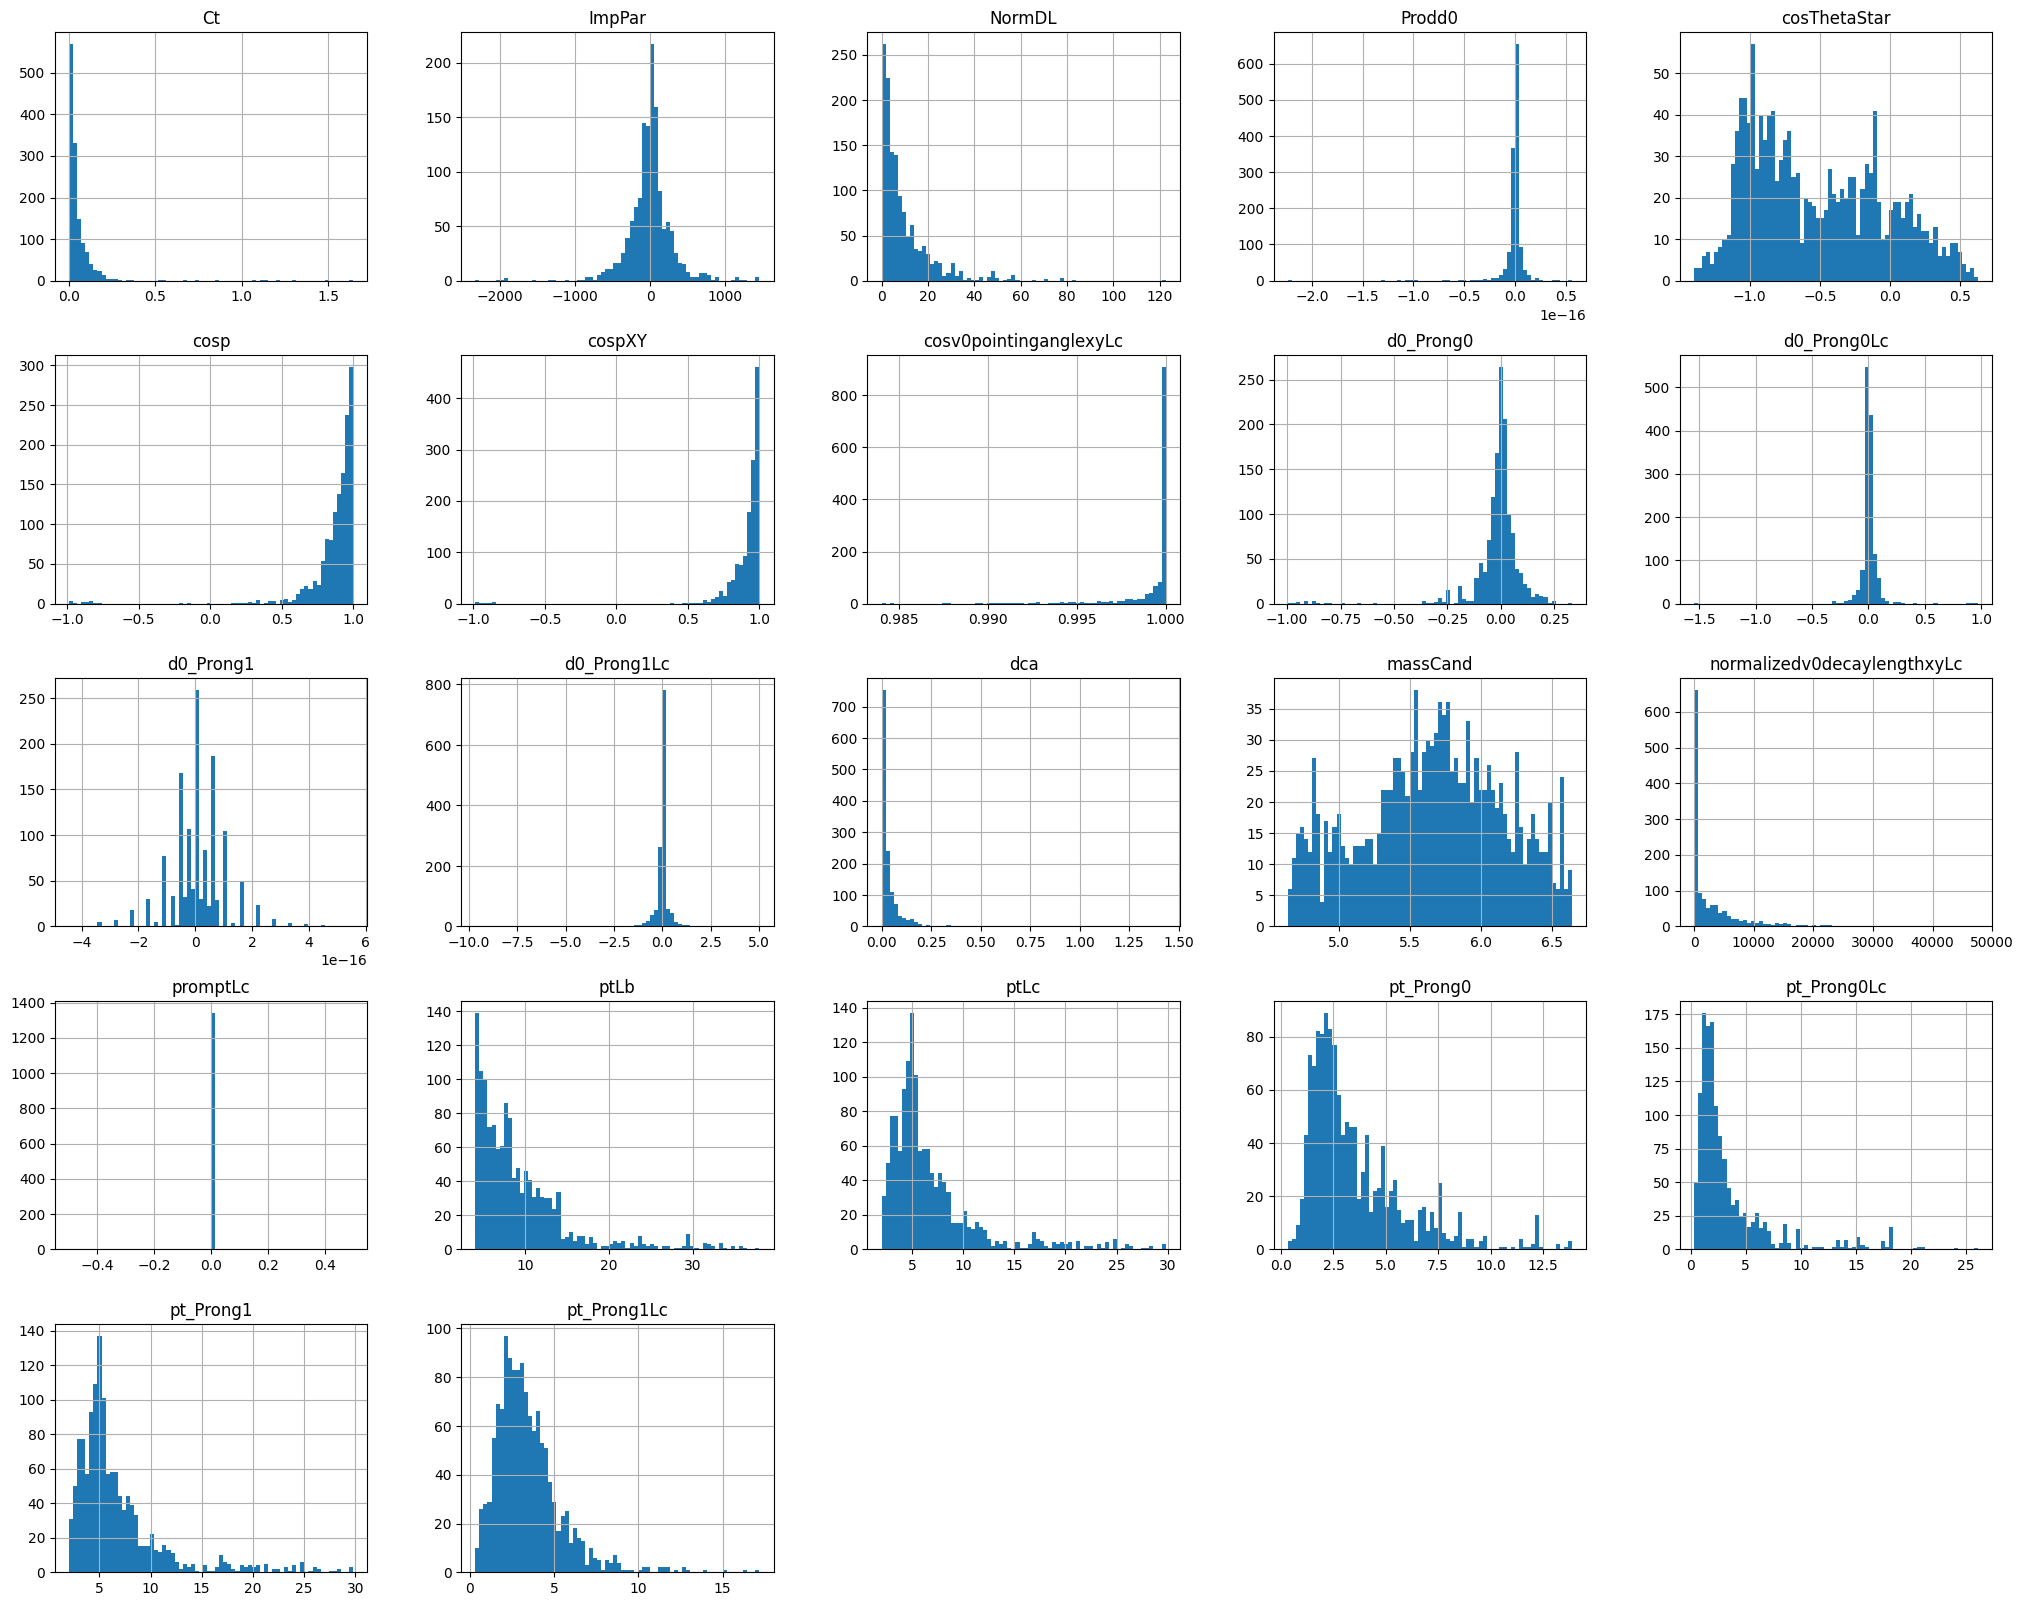

In [21]:
hist_sig = sig_pd.hist(bins=70, figsize=(25,20))

In [10]:
ntuple_name_bkg = "Lbtask/fNtupleLambdabUPGBackground"
file_bkg = "/home/zefi-giannakoudi/venv/CAML/AnalysisResults.root"

bkg = ROOT.RDataFrame(ntuple_name_bkg, file_bkg)
print(f"{len(file_bkg)} ROOT files were successfully loaded into RDataFrame.")

53 ROOT files were successfully loaded into RDataFrame.


In [11]:
bkg.Describe()

Dataframe from TChain Lbtask/fNtupleLambdabUPGBackground in file /home/zefi-giannakoudi/venv/CAML/AnalysisResults.root

Property                Value
--------                -----
Columns in total           22
Columns from defines        0
Event loops run             0
Processing slots           16

Column                          Type    Origin
------                          ----    ------
Ct                              Float_t Dataset
ImpPar                          Float_t Dataset
NormDL                          Float_t Dataset
Prodd0                          Float_t Dataset
cosThetaStar                    Float_t Dataset
cosp                            Float_t Dataset
cospXY                          Float_t Dataset
cosv0pointinganglexyLc          Float_t Dataset
d0_Prong0                       Float_t Dataset
d0_Prong0Lc                     Float_t Dataset
d0_Prong1                       Float_t Dataset
d0_Prong1Lc                     Float_t Dataset
dca                          

In [12]:
min_mass_value_bkg = 4
max_mass_value_bkg = 7.5           
bins_mass_bkg = 70

hist_data_mass_bkg = bkg.Histo1D(("candidate_vMass_hist_bkg", "candidate_vMass_bkg Histogram", bins_mass, min_mass_value, max_mass_value),"massCand")

canvas_vMass_bkg = ROOT.TCanvas("canvas_mass", "Histogram", 800, 600)

hist_data_mass_bkg.SetFillColorAlpha(ROOT.kBlue, 0.3)
hist_data_mass_bkg.GetXaxis().SetTitle("massCand")
hist_data_mass_bkg.GetYaxis().SetTitle("Candidates")

hist_data_mass_bkg.Draw()
canvas_vMass_bkg.SaveAs("Invariant_Mass_Distribution_bkg.png")

Info in <TCanvas::Print>: png file Invariant_Mass_Distribution_bkg.png has been created


In [13]:
canvas_vMass_bkg.Close()

In [15]:
bkg_pd = pd.DataFrame( \
    bkg.AsNumpy(columns=[\
            "Ct","ImpPar","NormDL","Prodd0",\
            "cosThetaStar","cosp","cospXY","cosv0pointinganglexyLc",\
            "d0_Prong0","d0_Prong0Lc","d0_Prong1","d0_Prong1Lc","dca","massCand","normalizedv0decaylengthxyLc",\
            "promptLc","ptLb","ptLc","pt_Prong0","pt_Prong0Lc",\
            "pt_Prong1","pt_Prong1Lc"])
                      )
bkg_pd

,Ct,ImpPar,NormDL,Prodd0,cosThetaStar,cosp,cospXY,cosv0pointinganglexyLc,d0_Prong0,d0_Prong0Lc,...,dca,massCand,normalizedv0decaylengthxyLc,promptLc,ptLb,ptLc,pt_Prong0,pt_Prong0Lc,pt_Prong1,pt_Prong1Lc
0,0.018600,21.766125,0.665625,1.517650e-18,-0.667867,-0.986931,-0.991402,1.000000,0.013670,0.011533,...,0.017395,5.518410,1467.281738,0.0,4.862209,3.312611,1.611442,0.842117,3.312611,2.495751
1,0.033599,18.708027,0.548026,3.794124e-19,-0.719326,-0.924675,-0.998281,1.000000,0.013670,0.003389,...,0.017544,5.691432,1467.281738,0.0,4.857744,3.256763,1.611442,0.843621,3.256763,2.495751
2,0.020599,22.191607,0.716309,-1.138237e-18,-0.586111,-0.993396,-0.993378,1.000000,0.013670,0.002459,...,0.017254,5.057194,1467.281738,0.0,5.293974,3.743520,1.611442,1.262296,3.743520,2.495751
3,0.017794,26.155531,0.723516,-1.138237e-18,-0.591279,-0.981810,-0.978742,1.000000,0.013670,0.007536,...,0.017190,5.498300,1467.281738,0.0,4.067544,2.564731,1.611442,0.516528,2.564731,2.495751
4,0.008428,8.805072,0.736968,-0.000000e+00,-1.054429,-0.660247,-0.993560,0.999883,-0.007655,-0.001906,...,0.018480,4.651486,18132.544922,0.0,5.035739,5.584154,0.765188,3.557860,5.584154,2.031162
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20141743,0.025464,11.254082,1.204427,8.696848e-19,-1.234266,0.999308,0.998702,1.000000,0.012533,-0.004103,...,0.006446,4.705396,34448.437500,0.0,4.958409,5.292414,0.421499,0.513127,5.292414,4.900001
20141744,0.000884,-1.063541,0.028804,-4.429106e-20,-1.088582,-0.658337,0.523728,1.000000,-0.000532,-0.004103,...,0.005409,5.049530,34448.437500,0.0,5.676708,5.292414,1.229805,0.513127,5.292414,4.900001
20141745,0.004034,4.651264,0.562983,2.986999e-19,-1.158579,-0.995757,-0.993752,1.000000,0.004305,-0.004103,...,0.004608,4.666118,34448.437500,0.0,5.604074,5.292414,0.591451,0.513127,5.292414,4.900001
20141746,0.004795,-7.329630,0.591413,4.971796e-20,-1.131048,0.987064,0.981129,1.000000,-0.003583,1.139186,...,0.001910,5.012430,34448.437500,0.0,4.936383,4.879419,0.953858,0.334276,4.879419,4.900001


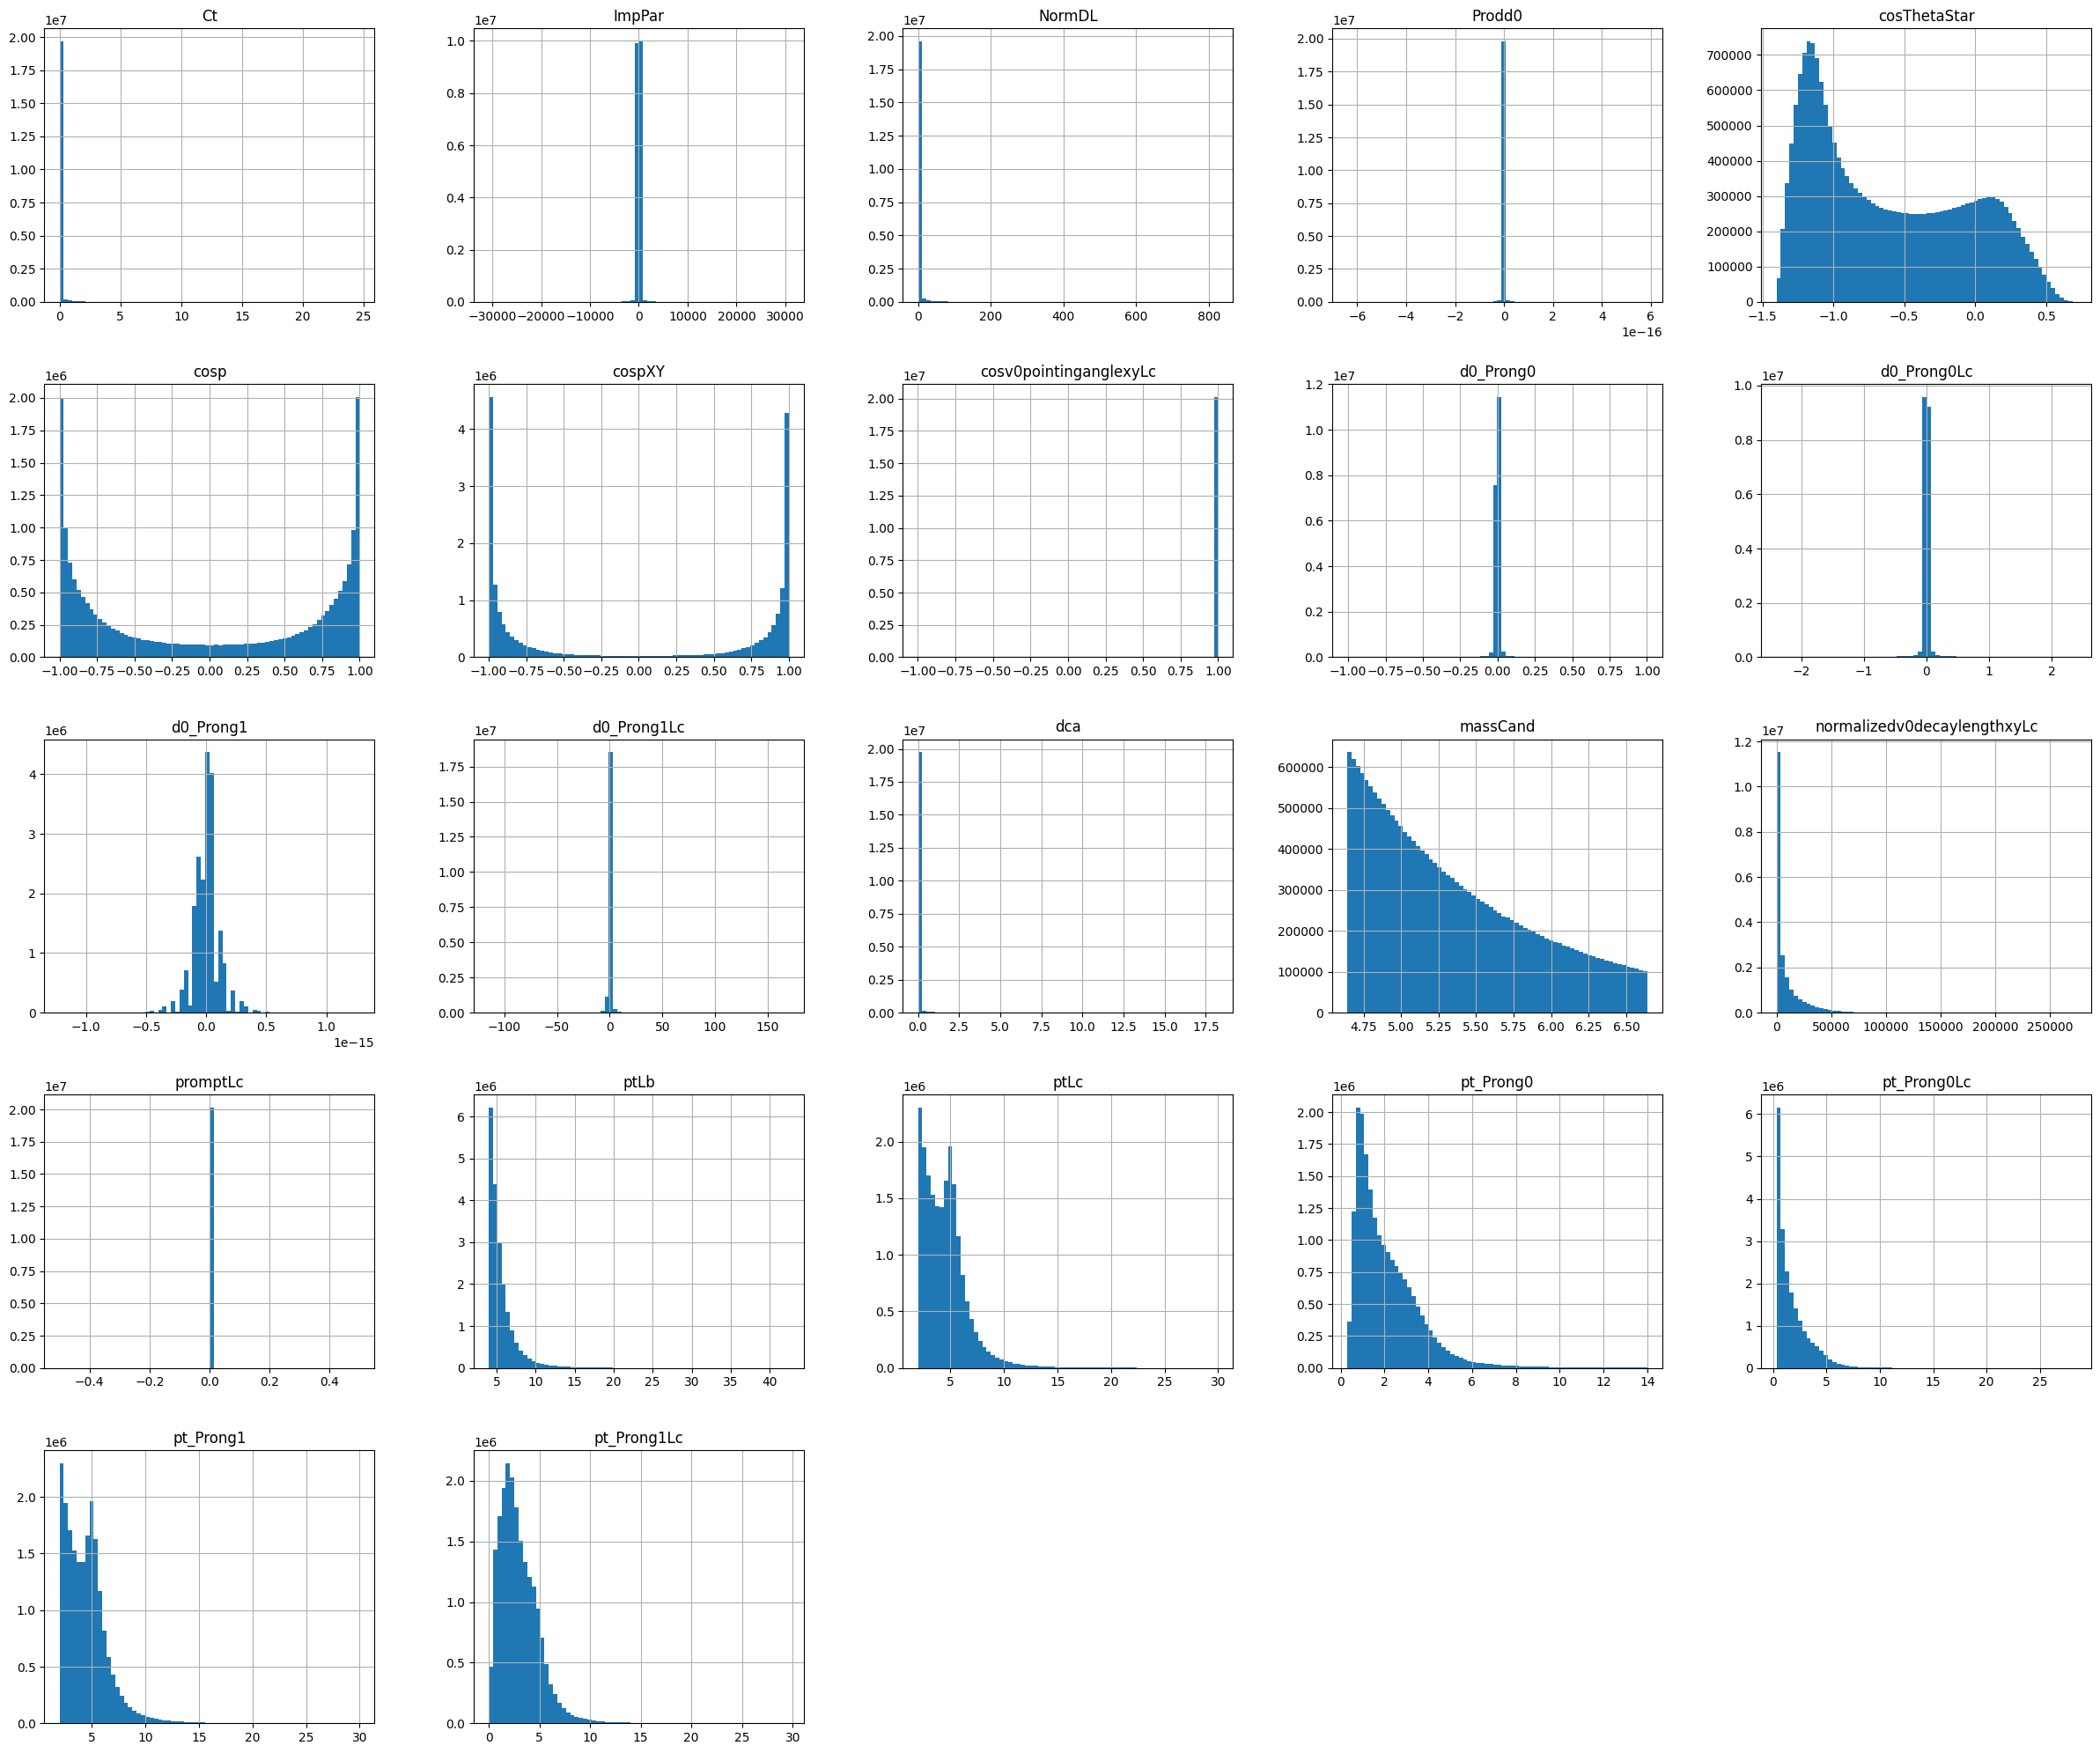

In [23]:
hist_bkg = bkg_pd.hist(bins=70, figsize=(30,25))